In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 로보플로우에 있는 데이터 가져오기
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="your_key")
project = rf.workspace("kwak-suna").project("26machinlearning")
version = project.version(1)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 121.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to 26MachinLearning-1 in yolov8:: 100%|██████████| 1753/1753 [00:00<00:00, 9844.45it/s]


In [3]:
# 학습
!pip install ultralytics

from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.train(data=f"{dataset.location}/data.yaml", epochs=50, imgsz=640)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/26MachinLearning-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=Fa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a01e4d86f20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [12]:
# 드라이브에 복사
!mkdir -p /content/drive/MyDrive/yolo_runs
!cp -r /content/runs/detect/train /content/drive/MyDrive/yolo_runs/train_backup

In [13]:
# 결과 확인
!ls /content/drive/MyDrive/yolo_runs/train_backup/weights

best.pt  last.pt


In [14]:
# 검증 데이터로 학습 도중 성능 확인
import pandas as pd
df = pd.read_csv("/content/runs/detect/train/results.csv")
df.columns = df.columns.str.strip()
print(df[["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(3))

    epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
47     48               0.96634            0.93804           0.96574   
48     49               0.96292            0.93881           0.96372   
49     50               0.96138            0.94860           0.96377   

    metrics/mAP50-95(B)  
47              0.88378  
48              0.87772  
49              0.87981  



image 1/36 /content/26MachinLearning-1/test/images/20261122_193952_jpg.rf.67310f4f7a30884a76179fd83f23dc09.jpg: 640x640 1 cat_doll, 11.6ms
image 2/36 /content/26MachinLearning-1/test/images/20261122_194220_jpg.rf.600d6bba0e5bc25156bdaf41f5527e08.jpg: 640x640 1 cat_doll, 13.4ms
image 3/36 /content/26MachinLearning-1/test/images/20261122_194311_jpg.rf.2128797062cd6981534bdc9d2a272ef9.jpg: 640x640 1 cat_doll, 8.6ms
image 4/36 /content/26MachinLearning-1/test/images/20261122_195617_jpg.rf.528300f86f952262ce54f833d655bd2d.jpg: 640x640 1 cat_doll, 8.1ms
image 5/36 /content/26MachinLearning-1/test/images/20261122_213937_jpg.rf.206a69e3a7524d09459bc054b40ec568.jpg: 640x640 1 cat_doll, 8.2ms
image 6/36 /content/26MachinLearning-1/test/images/20261122_213944_jpg.rf.b760c8a60bc8e1f3d51d328f41bcefd6.jpg: 640x640 1 cat_doll, 8.1ms
image 7/36 /content/26MachinLearning-1/test/images/20261122_214312_jpg.rf.d1bfcd5dcd3904a7585472f6962ac9b9.jpg: 640x640 1 cat_doll, 7.7ms
image 8/36 /content/26MachinLea

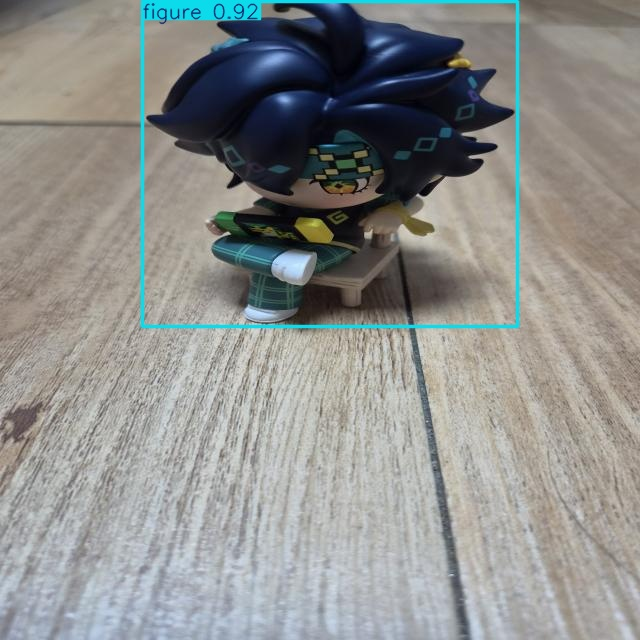

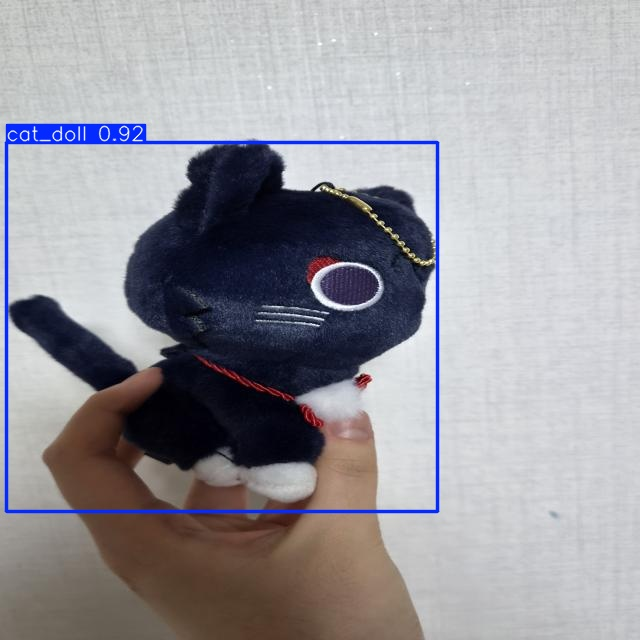

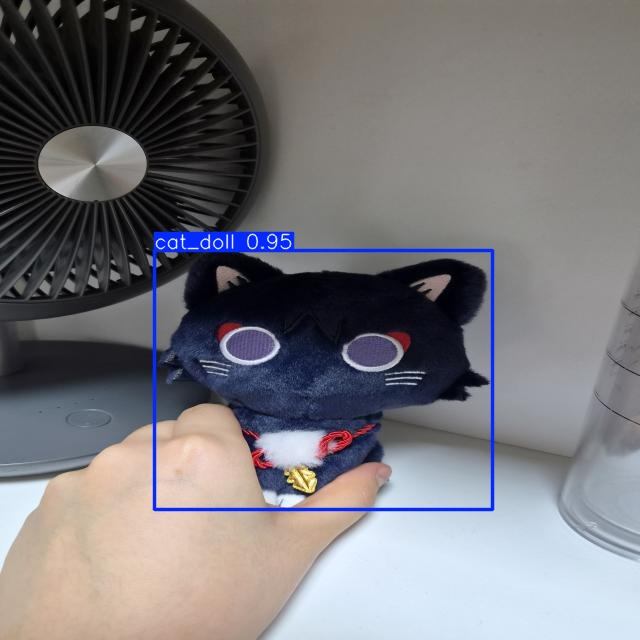

In [15]:

# 테스트
from ultralytics import YOLO
from IPython.display import Image, display
import glob

model = YOLO("/content/runs/detect/train/weights/best.pt")
results = model.predict(source=f"{dataset.location}/test/images", save=True, conf=0.5)

for p in glob.glob("/content/runs/detect/predict/*.jpg")[:3]:
    display(Image(filename=p))

In [16]:
metrics = model.val(data=f"{dataset.location}/data.yaml", split="test")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1656.1±449.9 MB/s, size: 40.8 KB)
val: Scanning /content/26MachinLearning-1/test/labels... 36 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 1.9Kit/s 0.0s
val: New cache created: /content/26MachinLearning-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.6it/s 1.2s
                   all         36         42      0.988      0.917      0.957      0.868
              cat_doll         16         16      0.993          1      0.995      0.948
                figure         13         14      0.987          1      0.995        0.9
                   pen         12         12      0.985       0.75      0.882      0.756
Speed: 4.2ms preprocess, 9.2ms inference, 0.0ms loss, 2.4ms postproce

In [18]:
results = model.track(
    source="/content/video.mp4",
    persist=True,
    tracker="bytetrack.yaml",
    conf=0.25,
    save=True,
    stream=True
)
for r in results:
    pass


video 1/1 (frame 1/552) /content/video.mp4: 640x384 (no detections), 30.4ms
video 1/1 (frame 2/552) /content/video.mp4: 640x384 (no detections), 49.1ms
video 1/1 (frame 3/552) /content/video.mp4: 640x384 (no detections), 51.5ms
video 1/1 (frame 4/552) /content/video.mp4: 640x384 (no detections), 31.7ms
video 1/1 (frame 5/552) /content/video.mp4: 640x384 (no detections), 44.1ms
video 1/1 (frame 6/552) /content/video.mp4: 640x384 (no detections), 39.2ms
video 1/1 (frame 7/552) /content/video.mp4: 640x384 (no detections), 47.5ms
video 1/1 (frame 8/552) /content/video.mp4: 640x384 (no detections), 53.5ms
video 1/1 (frame 9/552) /content/video.mp4: 640x384 (no detections), 27.7ms
video 1/1 (frame 10/552) /content/video.mp4: 640x384 (no detections), 16.7ms
video 1/1 (frame 11/552) /content/video.mp4: 640x384 (no detections), 23.2ms
video 1/1 (frame 12/552) /content/video.mp4: 640x384 (no detections), 10.3ms
video 1/1 (frame 13/552) /content/video.mp4: 640x384 (no detections), 16.3ms
video 1

In [19]:
# 집파일로 만들기
!mkdir -p /content/submit/results /content/submit/video
!cp /content/runs/detect/train/weights/best.pt /content/submit/
!cp /content/runs/detect/train/results.png /content/runs/detect/train/confusion_matrix.png /content/runs/detect/train/results.csv /content/submit/results/
!cp /content/video.mp4 /content/submit/video/input_video.mp4
!cp -r /content/runs/detect/track /content/submit/video/track_result
!cp /content/trajectory.csv /content/submit/results/ 2>/dev/null
!cd /content && zip -r submit.zip submit

  adding: submit/ (stored 0%)
  adding: submit/best.pt (deflated 9%)
  adding: submit/video/ (stored 0%)
  adding: submit/video/track_result/ (stored 0%)
  adding: submit/video/track_result/video.avi (deflated 2%)
  adding: submit/video/input_video.mp4 (deflated 0%)
  adding: submit/results/ (stored 0%)
  adding: submit/results/results.png (deflated 7%)
  adding: submit/results/results.csv (deflated 61%)
  adding: submit/results/confusion_matrix.png (deflated 32%)


In [20]:
from google.colab import files
files.download("/content/submit.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>